In [2]:
import pandas as pd
df = pd.read_csv('../data/raw/listings.csv')
df_redline = df[df['market_hash_name'] == 'AK-47 | Redline (Field-Tested)'].copy()
print(df_redline.shape)

(550, 18)


After dedup: 108


<Axes: xlabel='float_value', ylabel='price_usd'>

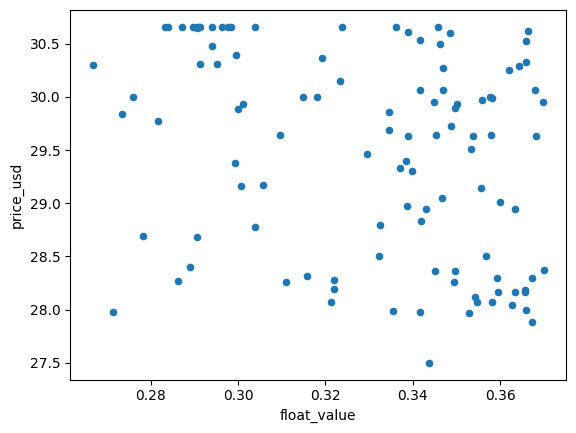

In [3]:
import matplotlib.pyplot as plt

df_redline = df_redline.sort_values('timestamp').drop_duplicates(
    subset='listing_id', keep='last'
).copy()
print("After dedup:", len(df_redline))

df_redline.plot.scatter(x='float_value', y='price_usd')


In [4]:
print("Total rows:", len(df_redline))
print("Unique listing IDs:", df_redline['listing_id'].nunique())
print("Unique timestamps:", df_redline['timestamp'].nunique())

Total rows: 108
Unique listing IDs: 108
Unique timestamps: 4


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

model = LinearRegression()
X = df_redline[['float_value']]
y = df_redline['price_usd']
model.fit(X, y)

pred = model.predict(X)
r2 = r2_score(y, pred)

print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)
print("R^2:", r2)